# Border 2 Fire — EnKF Experiment (`border2_experiment.ipynb`)

Uses **real WFIGS perimeters** and **derived UTC observation timestamps** anchored
to CAL FIRE incident reports and NASA FIRMS hotspot detections.

| Obs | UTC timestamp | Acres | Source |
|-----|--------------|-------|--------|
| t0 | 2025-01-23 18:22 | ~first detection | FIRMS Landsat 9 |
| t1 | 2025-01-24 20:36 | 4 250 | CAL FIRE 12:36 PM PT update |
| t2 | 2025-01-25 03:49 | 6 273 | CAL FIRE 7:49 PM PT update |
| t3 | 2025-01-27 00:12 | 6 625 | CAL FIRE 4:12 PM PT update |

Calls `step()` from `enkf.py` which runs `run_ensemble` (parallel FARSITE) → `enkf_update` (EnKF math).
Logs three CSV files for the agentic orchestrator's cost/accuracy models: `members.csv`, `steps.csv`, `prep.csv`.

# Imports & Configuration

In [1]:
import sys
sys.path.insert(0, 'src')

import csv
import time
import uuid
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from enkf import step as enkf_step, save_enkf_state, load_enkf_state
from geometry import geom_to_state, state_to_geom, align_states
from config import OUTPUT_DIR, DATA_DIR, DEFAULT_DIST_RES, DEFAULT_PERIM_RES
from firemap import query_weather_for_timestep
from farsite import FARSITE_TMP_DIR  # src/tmp/
from orchestrator.checks import finite_readings, mean_direction_deg, mean_speed

print('Imports OK')

Imports OK


In [2]:
# ============================================================================
# CLEANUP — run once before a fresh experiment to clear previous run outputs
# ============================================================================

FIRE_NAME = 'Border_2_Real'

# 1. FARSITE intermediate files (tmp/)
tmp_dir = Path(FARSITE_TMP_DIR)
if tmp_dir.exists():
    n = sum(1 for _ in tmp_dir.rglob('*'))
    shutil.rmtree(tmp_dir)
    tmp_dir.mkdir(parents=True, exist_ok=True)
    print(f'✓ Cleared {n} files from {tmp_dir}')
else:
    print(f'  tmp/ does not exist, nothing to clear')

# 2. Previous run CSV logs + checkpoint pkl
log_dir = OUTPUT_DIR / FIRE_NAME
if log_dir.exists():
    for f in ['members.csv', 'steps.csv', 'prep.csv',
              f'{FIRE_NAME}_enkf_results.pkl']:
        p = log_dir / f
        if p.exists():
            p.unlink()
            print(f'✓ Deleted {p.name}')
else:
    print(f'  {log_dir} does not exist, nothing to clear')

print('\nReady for a clean run.')

✓ Cleared 0 files from /home/jovyan/work/digital-twin-group/wildfire-digital-twin/src/tmp
✓ Deleted members.csv
✓ Deleted steps.csv
✓ Deleted prep.csv
✓ Deleted Border_2_Real_enkf_results.pkl

Ready for a clean run.


## Observation Timestamps

These UTC timestamps were derived by cross-referencing CAL FIRE incident update
acreage reports with the WFIGS perimeter acreages, and anchoring `t0` to the
first NASA FIRMS Landsat 9 hotspot detection.

In [3]:
OBS_TIMESTAMPS = [
    pd.Timestamp('2025-01-23 18:22:00', tz='UTC'),  # t0 — FIRMS ignition anchor
    pd.Timestamp('2025-01-24 20:36:00', tz='UTC'),  # t1 — CAL FIRE 12:36 PM PT (4,250 ac)
    pd.Timestamp('2025-01-25 03:49:00', tz='UTC'),  # t2 — CAL FIRE 7:49 PM PT  (6,273 ac)
    pd.Timestamp('2025-01-27 00:12:00', tz='UTC'),  # t3 — CAL FIRE 4:12 PM PT  (6,625 ac)
]

print('Observation timestamps:')
for i, ts in enumerate(OBS_TIMESTAMPS):
    print(f'  t{i}: {ts}')

Observation timestamps:
  t0: 2025-01-23 18:22:00+00:00
  t1: 2025-01-24 20:36:00+00:00
  t2: 2025-01-25 03:49:00+00:00
  t3: 2025-01-27 00:12:00+00:00


## Load Real Perimeters

In [4]:
PERIMETERS_PATH = DATA_DIR / 'border2_inputs' / 'border_2_perimeters.geojson'
LCP_PATH = str(DATA_DIR / 'border2_inputs' / 'landscape.lcp')
FIRE_NAME = 'Border_2_Real'

raw_gdf = gpd.read_file(PERIMETERS_PATH)
print(f'Raw perimeters: {len(raw_gdf)}')
print(raw_gdf[['datetime', 'acres']].to_string())

Raw perimeters: 6
    datetime        acres
0 2025-01-23          NaN
1 2025-01-23   567.000000
2 2025-01-23   566.339868
3 2025-01-24  4234.873545
4 2025-01-24  6272.660000
5 2025-01-26  6624.770000


### Assign Precise Timestamps and Reproject to EPSG:5070

WFIGS perimeters are in WGS84. FARSITE expects EPSG:5070 (Albers Equal Area).
Reprojecting here ensures `geom_to_state` stores EPSG:5070 coordinates.

In [5]:
# Select 4 representative perimeters (one per observation time)
SELECTED_IDX = [1, 3, 4, 5]

perimeters_gdf = raw_gdf.iloc[SELECTED_IDX].copy().reset_index(drop=True)
perimeters_gdf['obs_time'] = OBS_TIMESTAMPS
perimeters_gdf['obs_time'] = pd.to_datetime(perimeters_gdf['obs_time'], utc=True)

# Reproject to EPSG:5070 so geometry coordinates match LCP extent
perimeters_gdf = perimeters_gdf.to_crs('EPSG:5070')
print('CRS after reprojection:', perimeters_gdf.crs)

print('Selected perimeters with precise timestamps:')
for i, row in perimeters_gdf.iterrows():
    print(f'  [{i}] {row["obs_time"]}  bounds={row.geometry.bounds}')

CRS after reprojection: EPSG:5070
Selected perimeters with precise timestamps:
  [0] 2025-01-23 18:22:00+00:00  bounds=(-1932307.9862038032, 1270177.2506641382, -1930058.200045176, 1271825.3811061257)
  [1] 2025-01-24 20:36:00+00:00  bounds=(-1935511.6878793458, 1270171.4925100275, -1929892.4050902296, 1276188.986916912)
  [2] 2025-01-25 03:49:00+00:00  bounds=(-1935891.5206762566, 1270171.4808392834, -1929222.091653914, 1277003.6968184116)
  [3] 2025-01-27 00:12:00+00:00  bounds=(-1935891.5206762566, 1270171.4808392834, -1929222.091653914, 1277003.6968184116)


## Experiment Parameters

In [6]:
DIST_RES    = DEFAULT_DIST_RES   # meters (default 150)
PERIM_RES   = DEFAULT_PERIM_RES  # meters (default 150)

N_SAMPLES   = 300
N_VERTEX    = 20
N_WORKERS   = 12     # parallel FARSITE workers (ProcessPoolExecutor)
VSIZE       = 300.0  # observation noise std (m)
WSIZE       = 100.0  # model noise std (m)
RANDOM_SEED = 1234

# Default temperature/humidity for FARSITE (no API source)
DEFAULT_TEMPERATURE = 66    # °F
DEFAULT_HUMIDITY    = 0.08  # fraction

# Weather location (centroid of fire area in WGS84)
WX_LAT = 32.59588662537945
WX_LON = -116.85708741551528

# Sweep run ID — change this for each parameter sweep configuration
RUN_ID = str(uuid.uuid4())[:8]

rng = np.random.Generator(np.random.PCG64(RANDOM_SEED))

print('Parameters:')
print(f'  DIST_RES={DIST_RES}m  PERIM_RES={PERIM_RES}m')
print(f'  N_SAMPLES={N_SAMPLES}  N_VERTEX={N_VERTEX}  N_WORKERS={N_WORKERS}')
print(f'  VSIZE={VSIZE}m  WSIZE={WSIZE}m')
print(f'  RUN_ID={RUN_ID}')
print(f'  LCP_PATH={LCP_PATH}')
print(f'  LCP exists: {Path(LCP_PATH).exists()}')

Parameters:
  DIST_RES=150m  PERIM_RES=150m
  N_SAMPLES=300  N_VERTEX=20  N_WORKERS=12
  VSIZE=300.0m  WSIZE=100.0m
  RUN_ID=ddf0650a
  LCP_PATH=/home/jovyan/work/digital-twin-group/wildfire-digital-twin/data/border2_inputs/landscape.lcp
  LCP exists: True


## CSV Loggers

In [7]:
LOG_DIR = OUTPUT_DIR / FIRE_NAME
LOG_DIR.mkdir(parents=True, exist_ok=True)

MEMBERS_CSV = LOG_DIR / 'members.csv'
STEPS_CSV   = LOG_DIR / 'steps.csv'
PREP_CSV    = LOG_DIR / 'prep.csv'

# prep.csv is written directly here (data prep actions before the loop)
# members.csv and steps.csv are written inside enkf.step() automatically
PREP_FIELDS = ['action', 'step', 'detail', 'elapsed_s', 'status']
prep_f = open(PREP_CSV, 'w', newline='')
prep_w = csv.DictWriter(prep_f, fieldnames=PREP_FIELDS)
prep_w.writeheader()

print(f'Log directory: {LOG_DIR}')
print(f'  members.csv → written by enkf.step()')
print(f'  steps.csv   → written by enkf.step()')
print(f'  prep.csv    → written here')

Log directory: /home/jovyan/work/digital-twin-group/wildfire-digital-twin/outputs/Border_2_Real
  members.csv → written by enkf.step()
  steps.csv   → written by enkf.step()
  prep.csv    → written here


## Initialise EnKF State

In [8]:
_t0 = time.time()
current_state = geom_to_state(perimeters_gdf['geometry'].iloc[0])
X = 1000.0 * np.eye(2 * N_VERTEX)

prep_w.writerow(dict(
    action='init_state', step=-1,
    detail=f'initial perimeter -> {N_VERTEX} vertices, cov=1000*I',
    elapsed_s=round(time.time()-_t0, 3), status='ok'
))

print(f'State dimension : {2*N_VERTEX}')
print(f'Covariance shape: {X.shape}')
print(f'Initial state bounds: {state_to_geom(current_state).bounds}')

State dimension : 40
Covariance shape: (40, 40)
Initial state bounds: (-1932307.9862038032, 1270177.2506641382, -1930058.200045176, 1271825.3811061257)


## Results Storage

In [9]:
results = {
    'step':            [],
    't_start':         [],
    't_end':           [],
    'initial_geom':    [],
    'observed_geom':   [],
    'analysis_geom':   [],
    'covariance':      [],
    'valid_members':   [],
    'mean_ws':         [],
    'mean_wd':         [],
    'zkphat_ensemble': [],
    'xkphat_ensemble': [],
}

## Sequential Assimilation Loop

For each pair of consecutive observations:
1. Query weather for the interval
2. Sample wind speed/direction for the ensemble
3. `enkf_step(t, ...)` — calls `run_ensemble` (parallel FARSITE, `N_WORKERS` workers) → `enkf_update` (EnKF math)
4. Auto-logs to `members.csv` and `steps.csv` inside `enkf.step()`
5. Checkpoint `results` dict to disk after each step

In [10]:
n_timesteps = len(perimeters_gdf) - 1
print(f'Starting sequential assimilation for {n_timesteps} timesteps...')
print(f'N={N_SAMPLES}  workers={N_WORKERS}  res={DIST_RES}m  run_id={RUN_ID}')
print('=' * 70)

for t in range(n_timesteps):
    # Set checkpoint directory before step begins
    ckpt = log_dir / f'state_step{t}.npz'
    if ckpt.exists():
        d = np.load(ckpt)
        current_state, X = d['state'], d['X']
        print(f'  step {t} already complete, resuming from checkpoint')
        continue
        
    step_start = time.time()
    print(f'\n{"="*70}')
    print(f'STEP {t}  ->  {t+1}')
    print(f'{"="*70}')

    current_obs = perimeters_gdf.iloc[t]
    next_obs    = perimeters_gdf.iloc[t + 1]
    t_start     = current_obs['obs_time']
    t_end       = next_obs['obs_time']
    dt          = t_end - t_start
    

    print(f'  t_start : {t_start}')
    print(f'  t_end   : {t_end}')
    print(f'  dt      : {dt}')

    # -- Weather query -------------------------------------------------------
    _tw = time.time()
    try:
        ws_list, wd_list = query_weather_for_timestep(
            lat=WX_LAT, lon=WX_LON,
            start_time=t_start, end_time=t_end,
            verbose=False
        )
        # Drop readings the station did not report, keeping speed/direction
        # paired — a member needs both, and the two lists are parallel.
        n_raw = len(ws_list or [])
        ws_list, wd_list = finite_readings(ws_list, wd_list)
        n_dropped = n_raw - len(ws_list)
        if not ws_list:
            raise ValueError(f'no usable readings in window ({n_raw} all missing)')
        mean_ws = mean_speed(ws_list)
        mean_wd = mean_direction_deg(wd_list)      # circular, not arithmetic
        wx_status = 'ok' if not n_dropped else f'ok:dropped_{n_dropped}_of_{n_raw}'
        if n_dropped:
            print(f'  [wx] dropped {n_dropped} of {n_raw} readings with gaps; '
                  f'{len(ws_list)} usable, mean {mean_ws:.1f} mph @ {mean_wd:.0f} deg')
    except Exception as e:
        print(f'  [WARN] Weather query failed: {e}  — using fallback')
        ws_list = [10.0]
        wd_list = [225.0]
        mean_ws, mean_wd = 10.0, 225.0
        wx_status = f'fallback:{e}'
    prep_w.writerow(dict(
        action='query_weather', step=t,
        detail=f'ws={mean_ws:.1f} wd={mean_wd:.1f} n_obs={len(ws_list)}',
        elapsed_s=round(time.time()-_tw, 3), status=wx_status
    ))
    prep_f.flush()

    farsite_dt_minutes = 15 if mean_ws >= 25.0 else 30  # Shorter FARSITE steps when wind speed is heavy
    print(f'  farsite_dt_minutes : {farsite_dt_minutes}  (mean_ws {mean_ws:.1f} mph)')    
    # -- Sample weather for ensemble -----------------------------------------
    if len(ws_list) > 1:
        idx = rng.integers(0, len(ws_list), size=N_SAMPLES)
        sampled_ws = np.asarray(ws_list)[idx]
        sampled_wd = np.asarray(wd_list)[idx]
    else:
        sampled_ws = mean_ws + rng.normal(0, 2.0, size=N_SAMPLES)
        sampled_wd = mean_wd + rng.normal(0, 15.0, size=N_SAMPLES)
        sampled_ws = np.maximum(sampled_ws, 0)
        sampled_wd = np.fmod(sampled_wd + 360, 360)

    # -- Align observation state to current vertex count ---------------------
    observation_state = geom_to_state(next_obs['geometry'])
    observation_state, current_state = align_states(
        [observation_state, current_state], vertex_count=N_VERTEX
    )

    # -- FARSITE params ------------------------------------------------------
    enkf_params = {
        'temperature': DEFAULT_TEMPERATURE,
        'humidity':    DEFAULT_HUMIDITY,
    }

    # -- enkf_step -----------------------------------------------------------
    print(f'\nRunning enkf_step (N={N_SAMPLES}, workers={N_WORKERS})...')
    result = enkf_step(
        t                 = t,
        initial_state     = current_state,
        observation_state = observation_state,
        observation_time  = t_end,
        X                 = X,
        n_vertex          = N_VERTEX,
        n_samples         = N_SAMPLES,
        rng               = rng,
        sampled_wslst     = sampled_ws,
        sampled_wdlst     = sampled_wd,
        dt                = dt,
        vsize             = VSIZE,
        wsize             = WSIZE,
        dist_res          = DIST_RES,
        perim_res         = PERIM_RES,
        lcppath           = LCP_PATH,
        params            = enkf_params,
        n_workers         = N_WORKERS,
        members_csv       = MEMBERS_CSV,
        steps_csv         = STEPS_CSV,
        fire_name         = FIRE_NAME,
        run_id            = RUN_ID,
        farsite_dt_minutes=farsite_dt_minutes
    )

    adjusted_state  = result['adjusted_state']
    X               = result['X']
    zkphat_ensemble = result['zkphat_ensemble']
    xkphat_ensemble = result['xkphat_ensemble']
    n_valid         = result['n_valid']
    t_ensemble_s    = result['t_ensemble_s']
    t_enkf_s        = result['t_enkf_s']
    step_elapsed    = round(time.time() - step_start, 3)

    # Checkpoint
    np.savez(log_dir / f'state_step{t}.npz',
         state=current_state, X=X, t_obs=str(t_end))

    analysis_geom = state_to_geom(adjusted_state)
    obs_area_ac   = round(next_obs.geometry.area / 4046.86, 1)
    anal_area_ac  = round(analysis_geom.area / 4046.86, 1)

    print(f'  Valid members  : {n_valid}/{N_SAMPLES}')
    print(f'  Ensemble time  : {t_ensemble_s:.1f}s   EnKF time: {t_enkf_s:.1f}s')
    print(f'  Analysis area  : {anal_area_ac} ac  (observed: {obs_area_ac} ac)')
    print(f'  Step elapsed   : {step_elapsed:.1f}s')

    # -- Store results -------------------------------------------------------
    results['step'].append(t)
    results['t_start'].append(t_start)
    results['t_end'].append(t_end)
    results['initial_geom'].append(state_to_geom(current_state))
    results['observed_geom'].append(next_obs.geometry)
    results['analysis_geom'].append(analysis_geom)
    results['covariance'].append(X.copy())
    results['valid_members'].append(n_valid)
    results['mean_ws'].append(mean_ws)
    results['mean_wd'].append(mean_wd)
    results['zkphat_ensemble'].append(zkphat_ensemble.copy())
    results['xkphat_ensemble'].append(xkphat_ensemble.copy())

    pd.to_pickle(results, LOG_DIR / f'{FIRE_NAME}_enkf_results.pkl')
    print(f'  Checkpoint saved.')

    current_state = adjusted_state

print(f'\n{"="*70}')
print(f'SIMULATION COMPLETE — {len(results["step"])} steps')
print(f'{"="*70}')

Starting sequential assimilation for 3 timesteps...
N=300  workers=12  res=150m  run_id=ddf0650a

STEP 0  ->  1
  t_start : 2025-01-23 18:22:00+00:00
  t_end   : 2025-01-24 20:36:00+00:00
  dt      : 1 days 02:14:00
  farsite_dt_minutes : 30  (mean_ws 9.2 mph)

Running enkf_step (N=300, workers=12)...


Running ensemble:   9%|▊         | 26/300 [20:56<5:00:51, 65.88s/it] 

FARSITE output None at step 37/52


Running ensemble:   9%|▉         | 28/300 [24:08<5:45:50, 76.29s/it]

FARSITE output None at step 39/52


Running ensemble:  11%|█         | 32/300 [25:23<2:28:26, 33.23s/it]

... (258 outputs left out)

Running ensemble: 100%|█████████▉| 299/300 [7:13:35<03:29, 209.47s/it]

FARSITE output None at step 52/88


Running ensemble: 100%|██████████| 300/300 [7:15:52<00:00, 87.18s/it] 

Ensemble done: 216/300 valid (26153.0s, 12 workers)
Valid samples: 216, Failed samples: 84
Calculating adjusted state (ensemble-space)
  Valid members  : 216/300
  Ensemble time  : 26153.0s   EnKF time: 0.0s
  Analysis area  : 5542.4 ac  (observed: 6591.0 ac)
  Step elapsed   : 26155.5s
  Checkpoint saved.

SIMULATION COMPLETE — 3 steps


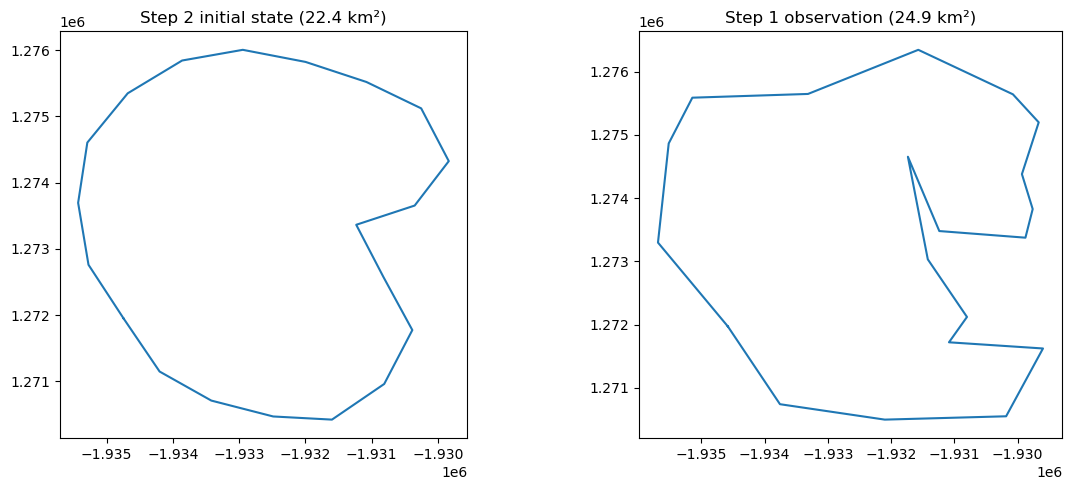

In [11]:
import matplotlib.pyplot as plt
from geometry import state_to_geom

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

geom = state_to_geom(current_state)
x, y = geom.exterior.xy
axes[0].plot(x, y)
axes[0].set_title(f'Step 2 initial state ({geom.area/1e6:.1f} km²)')
axes[0].set_aspect('equal')

obs_geom = state_to_geom(observation_state)
ox, oy = obs_geom.exterior.xy
axes[1].plot(ox, oy)
axes[1].set_title(f'Step 1 observation ({obs_geom.area/1e6:.1f} km²)')
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

step 2: 300 members, 84 failed (28.0%)

by status:
status
ok                216
farsite_failed     84

wind speed (mph), failed members:
count    84.00
mean      4.11
std       0.79
min       2.38
25%       3.42
50%       4.16
75%       4.66
max       5.75

wind speed (mph), succeeded:
count    216.00
mean       3.43
std        0.98
min        0.58
25%        2.78
50%        3.44
75%        4.07
max        6.18


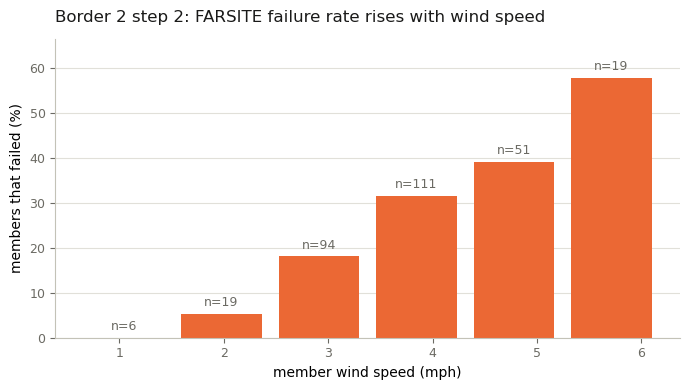

In [13]:
# --- Do FARSITE member failures track wind speed? -------------------------
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('outputs/Border_2_Real/members.csv')

# The column was renamed when the units were corrected: it always held mph,
# but older files call it wind_speed_ms. Accept either so backed-up runs load.
WIND = 'wind_speed_mph' if 'wind_speed_mph' in df.columns else 'wind_speed_ms'

# status is 'ok', 'farsite_failed', or 'error:<exception>'. Filtering on
# 'farsite_failed' alone silently drops members that died from an exception.
df['failed'] = df['status'] != 'ok'

STEP = 2
step = df[df['step'] == STEP].copy()
ok, bad = step[~step['failed']], step[step['failed']]

print(f"step {STEP}: {len(step)} members, {len(bad)} failed ({len(bad)/len(step):.1%})")
print("\nby status:")
print(step['status'].value_counts().to_string())
print(f"\nwind speed (mph), failed members:\n{bad[WIND].describe().round(2).to_string()}")
print(f"\nwind speed (mph), succeeded:\n{ok[WIND].describe().round(2).to_string()}")

# --- failure rate by wind speed ------------------------------------------
ORANGE, INK, MUTED, GRID = '#eb6834', '#1a1a19', '#6b6a63', '#e1e0d9'

step['bin'] = pd.cut(step[WIND], bins=6)
rate = (step.groupby('bin', observed=True)
            .agg(rate=('failed', 'mean'), n=('failed', 'size'))
            .reset_index())
centres = [iv.mid for iv in rate['bin']]
width = (centres[1] - centres[0]) * 0.82 if len(centres) > 1 else 1.0

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(centres, rate['rate'] * 100, width=width, color=ORANGE)

# n per bin as a direct label: the rate alone hides that the top bin may be thin
for x, r, n in zip(centres, rate['rate'], rate['n']):
    ax.text(x, r * 100 + max(rate['rate'] * 100) * 0.03, f'n={n}',
            ha='center', fontsize=9, color=MUTED)

ax.set_xlabel('member wind speed (mph)')
ax.set_ylabel('members that failed (%)')
ax.set_title(f'Border 2 step {STEP}: FARSITE failure rate rises with wind speed',
             loc='left', color=INK, fontsize=12, pad=12)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color('#c3c2b7')
ax.tick_params(colors=MUTED, labelsize=9)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

## Finalise Logs

In [14]:
prep_f.close()

print('prep.csv closed.')
print(f'  {PREP_CSV}')
print()
print('members.csv and steps.csv were written incrementally by enkf.step().')
print(f'  {MEMBERS_CSV}')
print(f'  {STEPS_CSV}')

prep.csv closed.
  /home/jovyan/work/digital-twin-group/wildfire-digital-twin/outputs/Border_2_Real/prep.csv

members.csv and steps.csv were written incrementally by enkf.step().
  /home/jovyan/work/digital-twin-group/wildfire-digital-twin/outputs/Border_2_Real/members.csv
  /home/jovyan/work/digital-twin-group/wildfire-digital-twin/outputs/Border_2_Real/steps.csv


## Summary Statistics

In [15]:
steps_df   = pd.read_csv(STEPS_CSV)
members_df = pd.read_csv(MEMBERS_CSV)

print('=== Step Summary ===')
print(steps_df[['step', 't_obs', 'N', 'n_valid', 't_ensemble_s', 't_enkf_s']].to_string(index=False))

valid_rate = (members_df['status'] == 'ok').mean() * 100
print(f'\nMean valid member rate : {valid_rate:.1f}%')
print(f'Total FARSITE runs     : {len(members_df)}')
print(f'Total ensemble time    : {steps_df.t_ensemble_s.sum():.1f}s')
print(f'Mean wall_s per member : {members_df.wall_s.mean():.2f}s')

=== Step Summary ===
 step                     t_obs   N  n_valid  t_ensemble_s  t_enkf_s
    0 2025-01-24 20:36:00+00:00 300      248     15723.984     0.402
    1 2025-01-25 03:49:00+00:00 300      300       950.213     0.012
    2 2025-01-27 00:12:00+00:00 300      216     26153.029     0.010

Mean valid member rate : 84.9%
Total FARSITE runs     : 900
Total ensemble time    : 42827.2s
Mean wall_s per member : 545.41s


## Visualise Results

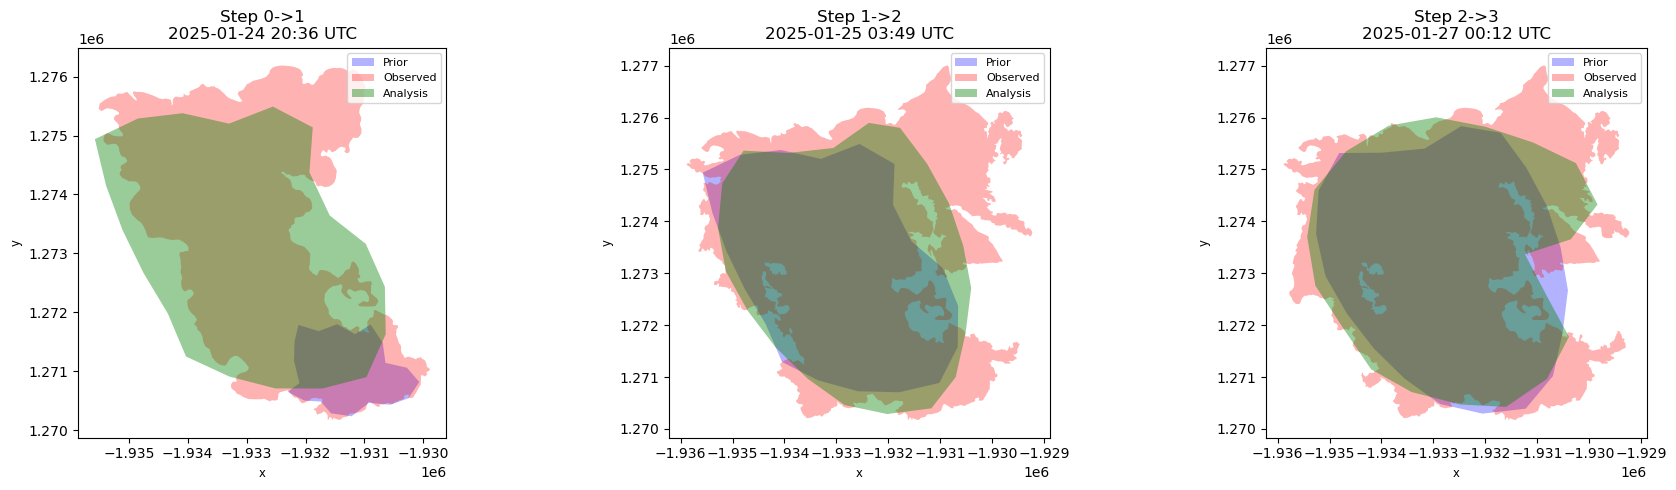

Figure saved.


In [16]:
fig, axes = plt.subplots(1, len(results['step']), figsize=(6*len(results['step']), 5))
if len(results['step']) == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    t = results['step'][i]
    gpd.GeoSeries([results['initial_geom'][i]]).plot(ax=ax, color='blue',  alpha=0.3, label='Prior')
    gpd.GeoSeries([results['observed_geom'][i]]).plot(ax=ax, color='red',   alpha=0.3, label='Observed')
    gpd.GeoSeries([results['analysis_geom'][i]]).plot(ax=ax, color='green', alpha=0.4, label='Analysis')
    ax.set_title(f'Step {t}->{t+1}\n{results["t_end"][i].strftime("%Y-%m-%d %H:%M UTC")}')
    ax.legend(fontsize=8)
    ax.set_aspect('equal')

plt.tight_layout()
plt.savefig(LOG_DIR / f'{FIRE_NAME}_perimeters.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved.')